# Programming Assignment 3, IT 540: Neural Network
### # 80 points, + max 4 points extra credit.

 PLEASE READ EVERY SINGLE COMMENT IN THIS FILE. 
 
 **Before doing anything else, make a copy of this file, add your name to the filename, and work with the copy. That way, if you make a serious error you can view the original that is still on your computer.**


 In what follows, it should be clear where you should place YOUR code. For example, if you see something like this:
 
 #### someVariable = # Finish this line of code
 
 then you need to replace the comment portion with executable Python code, for example:
 
 #### someVariable = 5

 IMPORTANT:  Make sure THIS code file is in the same directory
             as where your input data is.  If you do not, then you will get
             an error message when you try to read in your data.

 When you read your data in, it matters whether your data has a header
 row or not. If it's a header row that contains column names instead of data values, then pandas needs to know it's a header in order to (a) display it properly, and (b) make the correct computations with it.
 
 The default for pd.read_csv is such that pandas will attempt to infer whether there is a header or not. (Very useful, right?) It usually works correct, but if you get weird results, you'll need to inform pandas explicity if there is a header row or not. 
 
### Part 1: Read and explore the data.

Every modeling project should include at least some data exploration to assure that you understand the data.  Sometimes such data exploration can take a signicant amount of time, but we will keep it short for this assignment.

#### If you get any errors in the next cell, you may have to install (or upgrade) some packages.

For example, even though the code (that I wrote!) below was working a month ago, I got this error when I tried to run it again during Week 4 of our class:

"ImportError: To use Keras, you need to have `optree` installed."


Therefore, I did 'pip install optree', but then I got additional errors and had to do this, even though I had typing_extensions installed already:

pip install typing_extensions==4.7.1 --upgrade

In [1]:
# Set up environment 

import matplotlib.pyplot as plt
import numpy             as np
#import optree
import pandas            as pd
import tensorflow        as tf
print('tensorflow version:', tf.__version__)

import sklearn
from   sklearn.model_selection import train_test_split
from   sklearn.preprocessing   import MinMaxScaler, PowerTransformer, StandardScaler

import keras
print('keras version:', keras.__version__)
from   keras.layers            import Dense, Dropout, Input, BatchNormalization

%matplotlib inline
plt.style.use('ggplot')                  # ggplot is an R package that is MUCH easier to learn than matplotlib, and 
                                         # in many respects creates nicer graphics. This line tells matplotlib
                                         # to make its graphs look similar to those produced by ggplot.
plt.rcParams['axes.edgecolor'] = 'black'

tensorflow version: 2.20.0
keras version: 3.12.0


In [2]:
# Task 1: 5 points.  

# 2 points: Load the data that you downloaded from the Walsh server.
# 2 points: Use pandas 'display' and 'head' to display just 1 row of matmobData 
#           If you don't know how to display just 1 row, then look at the pandas 
#           documentation for df.head().
# 1 point:  Write a print statement with a message that shows how many rows and columns there are.


matmobData = pd.read_csv('matmob.data.sample.csv')

# add a line of code here to do the display

display(matmobData.head(1))
# add a line of code here to do the print with a computed values for the rows and columns

num_rows, num_cols = matmobData.shape
print(f"The dataset contains {num_rows} rows and {num_cols} columns")

,w.mat.mean,w.mat.sd,b.mat.mean,b.mat.sd,w.mob.mean,w.mob.sd,b.mob.mean,b.mob.sd,result,valid.games.row,w.mat.vector,b.mat.vector,w.mob.vector,b.mob.vector,pgn,half.moves
0,28.166667,8.850414,28.135417,9.671031,39.3125,12.951885,27.125,11.296064,1-0,1343406,"39, 39, 39, 39, 39, 39, 39, 39, 38, 38, 38, 38...","39, 39, 39, 39, 39, 39, 39, 38, 38, 38, 38, 38...","20, 28, 30, 32, 30, 40, 40, 45, 49, 47, 49, 51...","20, 22, 28, 34, 34, 35, 31, 32, 33, 30, 30, 28...",1.d4 Nf6 2.c4 e6 3.Nf3 d5 4.cxd5 exd5 5.Qc2 Be...,95


The dataset contains 100000 rows and 16 columns


#### You should see from the output that there are 100,000 rows and 16 columns. If you do not see a header row, then change your read_csv appropriately to see it.

result
0-1        27705
1-0        36485
1/2-1/2    35810
Name: result, dtype: int64


/var/folders/bf/0snrwrp56w553fm68kf18q000000gn/T/ipykernel_8616/1017027564.py:36: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  bWins     = resultCounts[0]  # This should return the number of games won by black
/var/folders/bf/0snrwrp56w553fm68kf18q000000gn/T/ipykernel_8616/1017027564.py:37: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  wWins     = resultCounts[1]  # won by white
/var/folders/bf/0snrwrp56w553fm68kf18q000000gn/T/ipykernel_8616/1017027564.py:38: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with

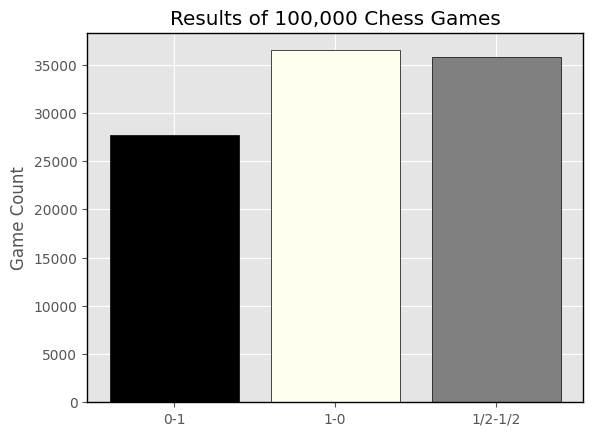

In [3]:
# Task 2, 15 points

# 5 points for the groupby, 
# 5 points for the counts and 
# 5 points for the bar chart

# Use plt.bar to create a matplotlib bar chart for the distribution of black wins, 
# white wins and draws from the sample data's game outcome variable, which is called 'result'. 

# In the result variable, a win by black is written as "0-1".  
# A white win is written as "1-0" and a draw is written as "1/2-1/2".  
# We will use those values to label the 3 bars in your plot.

# I have defined a partial function definition to display this bar chart.
# You need to fill in 2 sections of incomplete code.  In the first section
# Set the variable 'resultGroups' to a pandas 'groupby' object that 
# references the 'result' variable of the input gamesDF.
# Set the variable 'resultCounts' by referenceing the 'result' of that
# groupby object in 'resultGroups' and calling its 'count()' method.
# Then further below, you'll have to add a line for the bar chart.
# If this is not making sense to you, then simply do a web search for examples
# of how to group discrete values of a pandas Series (column) and get the count for each group.

def graphResults(gamesDF, plotTitle):
    '''Plot and save graph of game outcomes'''
    # gamesDF:   data frame of games 
    # plotTitle: string for graph title  
    
    
    resultGroups = gamesDF.groupby('result') # put your code here for the groupby
    resultCounts = resultCounts = resultGroups['result'].count() # put your code here for the counts
    
    
    print(resultCounts) # print each of the 3 outcomes followed their game counts

    bWins     = resultCounts[0]  # This should return the number of games won by black
    wWins     = resultCounts[1]  # won by white
    draws     = resultCounts[2]  # draws

    xLabels   = ['0-1',   '1-0',   '1/2-1/2']
    yCounts   = [bWins,    wWins,  draws]
    barColors = ['black', 'ivory', 'gray']
    
#    plt.figure(dpi=300) # If you uncomment this, you'll see a larger and higher-resolution image
    plt.ylabel("Game Count")
    
    ################ call plt.bar and pass it xLabels and yCounts,    ################
    #                set 'color' parameter to the barColors variable,                #
    #                and set the 'edgecolor' param to 'black'                        #
    #                                                                                #
    plt.bar(xLabels, yCounts, color=barColors, edgecolor='black')
    ##################################################################################
    
    plt.title(plotTitle)
    plt.show()

graphResults(matmobData, 'Results of 100,000 Chess Games')

### Part 2: Data Preparation

It is not uncommon to also spend a significant amount of time performing data preparation. This is often called 'data engineering', 'data munging', 'data wrangling', or 'data cleaning'. For example, there may be missing data (which we have already seen in the previous assignment), or doing other data modifications before it is ready for modeling.  We have several forms of data prep we must first do on our data before we can build a model to predict the game outcomes.

In [4]:
# Task 3, 5 points. 

# We only need the variables for the game mean of material 
# and mobility, the length (in half moves) of the games, and the game result 
# (which will, as indicated above, be '0-1' or '1-0' or '1/2-1/2') for black 
# win, white win, or draw. Consult the chess data description document to 
# identify which vars you need to keep and drop the rest.  

matmobData = matmobData[['w.mat.mean', 'b.mat.mean', 'w.mob.mean', 
                          'b.mob.mean', 'half.moves', 'result']] # put your code here. You'll need to keep 6 variables
display(matmobData)


,w.mat.mean,b.mat.mean,w.mob.mean,b.mob.mean,half.moves,result
0,28.166667,28.135417,39.312500,27.125000,95,1-0
1,33.851852,33.703704,37.185185,33.074074,53,1-0
2,31.301587,31.920635,32.625000,37.451613,62,0-1
3,21.878261,23.260870,27.172414,32.035088,114,0-1
4,34.775510,34.959184,41.040000,32.958333,48,1/2-1/2
...,...,...,...,...,...,...
99995,32.920000,33.580000,37.200000,34.560000,49,1/2-1/2
99996,34.800000,34.220000,36.760000,34.760000,49,1-0
99997,33.818182,34.000000,40.060606,32.909091,65,1-0
99998,33.920000,34.760000,41.840000,36.920000,49,1-0


In [5]:
# Task 4: 9 points
#   3 points each for:
#   a. saving the 'result' column into the Python variable 'result'
#   b. dropping the 'result' column from matmobData
#      You have already dropped a column in Assignment 2, but this time
#      you can refer to the column by its name, but you must also use axis=1 
#      to tell 'drop' that the name will be found in a column, not a row.
#   c. adding the new line of pandas code to convert 'result' into a 1-hot representation.
#      Simply call the pandas function 'get_dummies', giving it the new Python variable 'result'
#      (without the quotes, of course) and save the value back into the 'result' variable.

result     = matmobData['result']              # get the 'result' column
matmobData = matmobData.drop('result', axis=1)              # drop it from matmobData
result     = pd.get_dummies(result)             # Convert result to 1-hots

# Let's check our code:
display(matmobData) # the 'result' column should no longer be there
display(result) 

,w.mat.mean,b.mat.mean,w.mob.mean,b.mob.mean,half.moves
0,28.166667,28.135417,39.312500,27.125000,95
1,33.851852,33.703704,37.185185,33.074074,53
2,31.301587,31.920635,32.625000,37.451613,62
3,21.878261,23.260870,27.172414,32.035088,114
4,34.775510,34.959184,41.040000,32.958333,48
...,...,...,...,...,...
99995,32.920000,33.580000,37.200000,34.560000,49
99996,34.800000,34.220000,36.760000,34.760000,49
99997,33.818182,34.000000,40.060606,32.909091,65
99998,33.920000,34.760000,41.840000,36.920000,49


,0-1,1-0,1/2-1/2
0,False,True,False
1,False,True,False
2,True,False,False
3,True,False,False
4,False,False,True
...,...,...,...
99995,False,False,True
99996,False,True,False
99997,False,True,False
99998,False,True,False


In [6]:
# Task 5: 6 points. Use 85% of the data for training and 15% for testing.
# You will remember how to do this from Assignment 2. 
# Just as you did then, use a random state of 34 and shuffle=True

X_train, X_test, y_train, y_test = train_test_split(
    matmobData, result, test_size=0.15, random_state=34, shuffle=True)

# Let's check the data shapes:

print(f"X_train shape is {X_train.shape}")
print(f"y_train shape is {y_train.shape}")
print(f"X_test  shape is {X_test.shape}")
print(f"y_test  shape is {y_test.shape}")


X_train shape is (85000, 5)
y_train shape is (85000, 3)
X_test  shape is (15000, 5)
y_test  shape is (15000, 3)


Before scaling X_train variables are distributed like this:


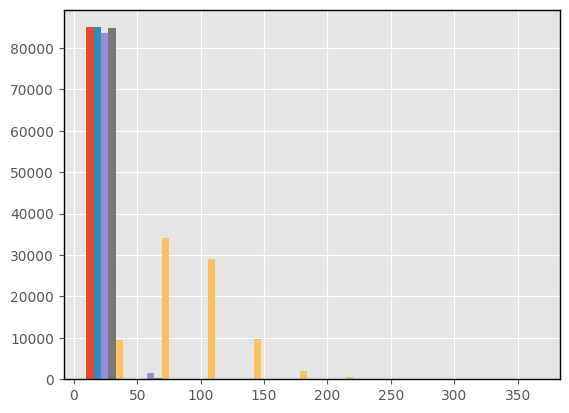

After scaling X_train they are distributed this way:


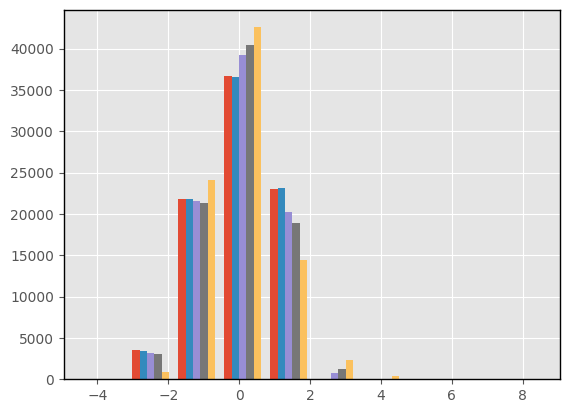

In [7]:
# Task 6: 10 points

# 2 points: set the 'scaler' variable
# 2 points: fit the scaler
# 2 points: transform X_train
# 2 points: transform X_test
# 1 point:  create a matplotlib histogram of X_train
# 1 point:  create a matplotlib histogram of X_trainScaled

# It is almost always necessary to convert your predictor values
# by normalizing them.  If you do not do this, then some variables may
# have values with huge ranges which may be interpreted by the 
# machine learning algorithm as more important than other variables
# that have smaller ranges.  

# There are two commonly used forms of normalization (but there are also other methods):
# min-max and standard scaling.  
# We will perform standard scaling which transforms every
# input variable to have a mean of 0 and a standard deviation of 1.

scaler = StandardScaler()   # YOUR CODE HERE. Set 'scaler' to an unfitted standard scaler (find the name of it in scikit-learn documentation)

scaler.fit(X_train) # ADD CODE ON THIS LINE TO FIT 'scaler' ON THE X_train DATA. There is no need to assign the result into a variable.

X_trainScaled = scaler.transform(X_train) # ADD YOUR CODE HERE TO CALL THE TRANSFORM METHOD OF 'scaler' ON THE X_train data
X_testScaled  = scaler.transform(X_test) # NOW TRANSFORM THE X_test DATA IN THE SAME WAY

print('Before scaling X_train variables are distributed like this:')
plt.hist(X_train) # ADD CODE ON THIS LINE TO CREATE A HISTOGRAM OF X_train
plt.show()

print('After scaling X_train they are distributed this way:')
plt.hist(X_trainScaled) # ADD CODE ON THIS LINE TO CREATE A HISTOGRAM OF X_trainScaled
plt.show()


In [8]:
# Task 7: 15 points

# 4 points each for the 3 layers
# 3 points for the model summary

# Build and train a sequential neural net that predicts 
# a game result from the other variable values. 

# You only need an Input layer, 
#   https://keras.io/api/layers/core_layers/input/
# and two Dense layers,
#   https://keras.io/api/layers/core_layers/dense/
#   one for a hidden layer and one for an output layer. 

#  Also, use the following hyperparameter value for your Input layer:
#  shape=(5,) which will tell the Input layer to expect 5 features.
# For the hidden layer, you'll need to use:
# a. units = 50 which tells it to use only 50 neurons (which is enough for this small network), and 
# b. activation = 'sigmoid' so it will use a sigmoid activation function for each hidden neuron.
#
# Your output layer will also be Dense and you MUST use these 2 hyperparameters:
# a. units = 3 (because we are predicting one of three game outcomes)
# b. activation = 'softmax'  Do you remember the softmax function? 
# We have discussed it already in class.

nnModel = keras.models.Sequential([  # This line defines the variable 'nnModel' 
                                     # to be a sequentially-defined neural net
  Input(shape=(5,)),  # Input layer with 5 features # ADD YOUR INPUT LAYER HERE
    Dense(units=50, activation='sigmoid'),  # Hidden layer with 50 neurons # ADD YOUR HIDDEN LAYER HERE
    # ADD YOUR OUTPUT LAYER HERE
    Dense(units=3, activation='softmax')  # Output layer with 3 classes 
])  
    
nnModel.summary()  # PUT A LINE OF CODE HERE TO SHOW THE MODEL'S SUMMARY (just call the summary method of 'nnModel')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 50)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           153 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 453 (1.77 KB)

 Trainable params: 453 (1.77 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
%%time

# Task 8: 15 points
# Compile, train and evaluate your model

# You will have to look this page for the documentation with simple examples 
# of all three of these sub-tasks:
# https://keras.io/api/models/model_training_apis/

# 5 points each for:
#  compile:  use the tf.keras.optimizers.SGD() optimizer for standard stochastic gradient descent
#            Also use "categorical_crossentropy" as the loss function,
#            and "accuracy" as the only metric
#  fit:      to train the model on X_trainScaled and y_train for 50 epochs
#  evaluate: on X_testScaled and y_test Note: Evaluate returns two values. 
#                                             Loss is the first and accuracy is the second


nnModel.compile(
    optimizer=tf.keras.optimizers.SGD(),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

nnModelHistory    = nnModel.fit(X_trainScaled, y_train, epochs=50, verbose=1)

testLoss, testAcc = nnModel.evaluate(X_testScaled, y_test)

print(f"\nTest Loss and Accuracy: {testLoss} {testAcc}")

Epoch 1/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 300us/step - accuracy: 0.4934 - loss: 1.0211
Epoch 2/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 301us/step - accuracy: 0.5284 - loss: 0.9675
Epoch 3/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 293us/step - accuracy: 0.5322 - loss: 0.9591
Epoch 4/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 295us/step - accuracy: 0.5343 - loss: 0.9556
Epoch 5/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 302us/step - accuracy: 0.5372 - loss: 0.9525
Epoch 6/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 293us/step - accuracy: 0.5411 - loss: 0.9490
Epoch 7/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 293us/step - accuracy: 0.5427 - loss: 0.9453
Epoch 8/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 295us/step - accuracy: 0.5460 - loss: 0.9413
Epoch 9/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 301us/step - accuracy: 0.5491 - loss: 0.9370
Epoch 10/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 296us/step - accuracy: 0.5532 - loss: 0.9320
Epoch 11/50
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1s 294us/step - accuracy: 0.5572 - loss: 0.9266
Epoch 12

In [16]:
# Task 9, 4 extra credit points.  

# Build a SECOND neural net that uses DIFFERENT 
# values for some of the following hyperparameters to try 
# and see if you can get even better results.  

# Once you get Tasks 7 and 8 working, just copy ALL of 
# that code down to here, but then either change the values of some of the following 
# before you actually train and evaluate its results, AND/OR try adding other
# hyperparameters to change their default values.  There is no guarantee
# that you will improve upon your previous results, and your grade does not
# depend upon doing better, but you should be able to do better. In either case,
# I just want to see you build, execute, and evaluate a DIFFERENT model.

# Some hyperparameters you can consider are:
#  1. units in your first hidden layer (do NOT change units in your output layer!)
#     Hint: in general, you'll get better results with more units, but it's also possible
#           it will overfit and get worse. You won't know until you try.
#  2. activation function in the hidden layer (do NOT change softmax in output layer)
#      You could try 'relu', or 'tanh', for example. There are also others.
#  3. optimizer. You could try Adam, Nadam, or Adagrad, for example.
#  4. epochs.  More epochs will often give you better results, but if you
#              do too many you may overfit.
#  5. batch_size.  The default is 32. Try smaller or larger.

# You could also try adding a 2nd hidden layer between the first 
# hidden layer and the output layer.

print("\n" + "="*80)
print("EXTRA CREDIT: Building an improved model")
print("="*80 + "\n")

# Build improved model with:
# - More neurons in hidden layer (100 instead of 50)
# - ReLU activation instead of sigmoid
# - Adam optimizer instead of SGD
# - Additional hidden layer

nnModel2 = keras.models.Sequential([
    Input(shape=(5,)),
    Dense(units=100, activation='relu'),  # First hidden layer - more neurons, ReLU
    Dense(units=50, activation='relu'),   # Second hidden layer
    Dense(units=3, activation='softmax')  # Output layer
])

nnModel2.summary()

# Compile with Adam optimizer
nnModel2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train with more epochs and smaller batch size
nnModelHistory2 = nnModel2.fit(
    X_trainScaled, y_train, 
    epochs=75, 
    batch_size=64,
    validation_split=0.1,  # Use 10% of training data for validation
    verbose=1
)

# Evaluate improved model
testLoss2, testAcc2 = nnModel2.evaluate(X_testScaled, y_test)

print(f"\nImproved Model Test Loss and Accuracy: {testLoss2} {testAcc2}")

# Compare models
print("\n" + "="*80)
print("MODEL COMPARISON")
print("="*80)
print(f"Original Model - Test Accuracy: {testAcc:.4f}")
print(f"Improved Model - Test Accuracy: {testAcc2:.4f}")
print(f"Improvement: {(testAcc2 - testAcc):.4f}")





EXTRA CREDIT: Building an improved model



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 100)            │           600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           153 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,803 (22.67 KB)

 Trainable params: 5,803 (22.67 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/75
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 1s 479us/step - accuracy: 0.5886 - loss: 0.8745 - val_accuracy: 0.6244 - val_loss: 0.8162
Epoch 2/75
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 1s 436us/step - accuracy: 0.6323 - loss: 0.8092 - val_accuracy: 0.6325 - val_loss: 0.8032
Epoch 3/75
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 1s 460us/step - accuracy: 0.6349 - loss: 0.8037 - val_accuracy: 0.6335 - val_loss: 0.8027
Epoch 4/75
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 1s 440us/step - accuracy: 0.6374 - loss: 0.8006 - val_accuracy: 0.6391 - val_loss: 0.7959
Epoch 5/75
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 1s 430us/step - accuracy: 0.6396 - loss: 0.7977 - val_accuracy: 0.6313 - val_loss: 0.8053
Epoch 6/75
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 1s 419us/step - accuracy: 0.6399 - loss: 0.7960 - val_accuracy: 0.6240 - val_loss: 0.8138
Epoch 7/75
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 1s 427us/step - accuracy: 0.6416 - loss: 0.7938 - val_accuracy: 0.6404 - val_loss: 0.7911
Epoch 8/75
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 1s 436us/step - accuracy: 0.6432 -